# 04. 실험 — 모델 깊이 비교

**목표**: Conv 블록 수(3 / 4 / 5)에 따른 성능 변화를 동일 조건에서 비교

In [1]:
import os, random
from pathlib import Path
from collections import defaultdict

import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from tqdm import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

RAW_DIR    = Path('/data_local') / 'raw'
CLASS_MAP  = {'고추': 'pepper', '배추': 'cabbage', '오이': 'cucumber'}
SPLITS     = ['Training', 'Validation']
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

def get_image_paths(raw_dir, splits, class_map):
    data = defaultdict(list)
    for split in splits:
        split_dir = raw_dir / split
        for folder in split_dir.iterdir():
            if not folder.is_dir() or '[원천]' not in folder.name:
                continue
            for kr_name, en_name in class_map.items():
                if kr_name in folder.name:
                    for f in folder.iterdir():
                        if f.suffix.lower() in IMAGE_EXTS:
                            data[en_name].append(f)
    return data

image_paths = get_image_paths(RAW_DIR, SPLITS, CLASS_MAP)

MAX_PER_CLASS = 2000
sampled_paths = {cls: random.sample(paths, MAX_PER_CLASS)
                 for cls, paths in image_paths.items()}

CLASS_NAMES  = list(sampled_paths.keys())
CLASS_TO_IDX = {cls: idx for idx, cls in enumerate(CLASS_NAMES)}
all_samples, all_labels = [], []
for cls, paths in sampled_paths.items():
    label = CLASS_TO_IDX[cls]
    for p in paths:
        all_samples.append((p, label))
        all_labels.append(label)

train_data, temp_data, _, temp_labels = train_test_split(
    all_samples, all_labels, test_size=0.2, stratify=all_labels, random_state=SEED)
val_data, test_data = train_test_split(
    temp_data, test_size=0.5, stratify=temp_labels, random_state=SEED)

SAMPLE_N     = 500
sample_paths = random.sample([p for p, _ in train_data],
                             min(SAMPLE_N * len(CLASS_NAMES), len(train_data)))
mean = np.zeros(3)
std  = np.zeros(3)
for path in sample_paths:
    img  = np.array(Image.open(path).convert('RGB').resize((224, 224))) / 255.0
    mean += img.mean(axis=(0, 1))
    std  += img.std(axis=(0, 1))
mean /= len(sample_paths)
std  /= len(sample_paths)
MEAN = mean.tolist()
STD  = std.tolist()

class CropDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples   = samples
        self.transform = transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label

IMG_SIZE   = 224
BATCH_SIZE = 32
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
train_loader = DataLoader(CropDataset(train_data, train_transform),
                          batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(CropDataset(val_data,   val_test_transform),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(CropDataset(test_data,  val_test_transform),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
print(f'train {len(train_data)}장 / val {len(val_data)}장 / test {len(test_data)}장')

Device : cuda
train 4800장 / val 600장 / test 600장


## 2. 모델 정의 — 3 / 4 / 5 Conv 블록

In [3]:
class ShallowCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1,1)), nn.Flatten(),
            nn.Linear(128, 64), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(64, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

class CurrentCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1,1)), nn.Flatten(),
            nn.Linear(256, 128), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(128, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

class DeepCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
            nn.Conv2d(256, 512, 3, padding=1), nn.BatchNorm2d(512), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1,1)), nn.Flatten(),
            nn.Linear(512, 256), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

for name, model in [('ShallowCNN(3블록)', ShallowCNN()), ('CurrentCNN(4블록)', CurrentCNN()), ('DeepCNN(5블록)', DeepCNN())]:
    params = sum(p.numel() for p in model.parameters())
    print(f'{name}: {params:,} 파라미터')

ShallowCNN(3블록): 102,147 파라미터
CurrentCNN(4블록): 422,659 파라미터
DeepCNN(5블록): 1,702,659 파라미터


## 3. 학습 함수

In [4]:
def train_model(model, epochs=50, patience=5):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc  = 0.0
    best_val_loss = float('inf')
    patience_cnt  = 0
    best_state    = None

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in tqdm(train_loader, desc=f'Epoch {epoch:02d}/{epochs} train', leave=False):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(images)
            loss    = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)
            _, preds = outputs.max(1)
            correct  += preds.eq(labels).sum().item()
            total    += labels.size(0)
        train_loss = running_loss / total
        train_acc  = correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc=f'Epoch {epoch:02d}/{epochs} val  ', leave=False):
                images, labels = images.to(DEVICE), labels.to(DEVICE)
                outputs = model(images)
                loss    = criterion(outputs, labels)
                running_loss += loss.item() * images.size(0)
                _, preds = outputs.max(1)
                correct  += preds.eq(labels).sum().item()
                total    += labels.size(0)
        val_loss = running_loss / total
        val_acc  = correct / total

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state   = {k: v.clone() for k, v in model.state_dict().items()}

        print(f'Epoch {epoch:02d}/{epochs}  train loss {train_loss:.4f} acc {train_acc:.4f}  val loss {val_loss:.4f} acc {val_acc:.4f}')

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_cnt  = 0
        else:
            patience_cnt += 1
            if patience_cnt >= patience:
                print(f'Early Stopping at epoch {epoch}')
                break

    model.load_state_dict(best_state)
    return model, history, best_val_acc

## 4. 실험 실행

In [5]:
results = {}

print('='*50)
print('ShallowCNN (3블록)')
print('='*50)
model_s, hist_s, acc_s = train_model(ShallowCNN(num_classes=len(CLASS_TO_IDX)))
results['ShallowCNN'] = {'history': hist_s, 'best_val_acc': acc_s,
                          'params': sum(p.numel() for p in ShallowCNN().parameters())}

print('\n' + '='*50)
print('CurrentCNN (4블록)')
print('='*50)
model_c, hist_c, acc_c = train_model(CurrentCNN(num_classes=len(CLASS_TO_IDX)))
results['CurrentCNN'] = {'history': hist_c, 'best_val_acc': acc_c,
                          'params': sum(p.numel() for p in CurrentCNN().parameters())}

print('\n' + '='*50)
print('DeepCNN (5블록)')
print('='*50)
model_d, hist_d, acc_d = train_model(DeepCNN(num_classes=len(CLASS_TO_IDX)))
results['DeepCNN'] = {'history': hist_d, 'best_val_acc': acc_d,
                       'params': sum(p.numel() for p in DeepCNN().parameters())}

ShallowCNN (3블록)


Epoch 01/50  train loss 0.5621 acc 0.7777  val loss 0.3872 acc 0.8633


Epoch 02/50  train loss 0.3816 acc 0.8533  val loss 0.2699 acc 0.9167


Epoch 03/50  train loss 0.3191 acc 0.8800  val loss 0.3753 acc 0.8700


Epoch 04/50  train loss 0.2717 acc 0.8992  val loss 0.2708 acc 0.9067


Epoch 05/50  train loss 0.2649 acc 0.9042  val loss 0.2541 acc 0.9167


... (45 outputs left out)

Epoch 07/50  train loss 0.1681 acc 0.9373  val loss 0.1919 acc 0.9417


Epoch 08/50  train loss 0.1672 acc 0.9390  val loss 0.2460 acc 0.9283


Epoch 09/50  train loss 0.1401 acc 0.9498  val loss 0.2087 acc 0.9350


Epoch 10/50  train loss 0.1431 acc 0.9485  val loss 0.1537 acc 0.9500
Early Stopping at epoch 10


## 5. 결과 비교

/tmp/ipykernel_8385/2586480786.py:16: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_8385/2586480786.py:16: UserWarning: Glyph 44368 (\N{HANGUL SYLLABLE GYO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_8385/2586480786.py:18: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.savefig(fig_path, dpi=150, bbox_inches='tight')
/tmp/ipykernel_8385/2586480786.py:18: UserWarning: Glyph 44368 (\N{HANGUL SYLLABLE GYO}) missing from font(s) DejaVu Sans.
  plt.savefig(fig_path, dpi=150, bbox_inches='tight')
/opt/conda/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/conda/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 44368 (\N{HANGUL SYLLABLE GYO}) missing from font(s) DejaVu Sans.
  fig

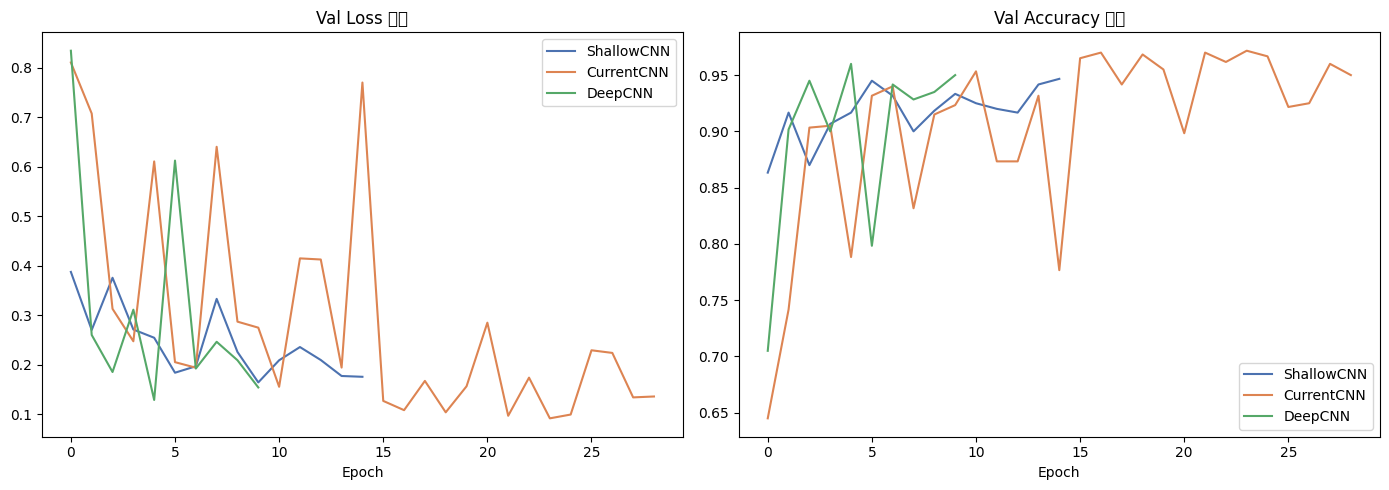


실험 결과 요약
모델                 파라미터   Best Val Acc
--------------------------------------
ShallowCNN      102,147         0.9467
CurrentCNN      422,659         0.9717
DeepCNN       1,702,659         0.9600


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {'ShallowCNN': '#4C72B0', 'CurrentCNN': '#DD8452', 'DeepCNN': '#55A868'}

for name, res in results.items():
    h = res['history']
    axes[0].plot(h['val_loss'], label=name, color=colors[name])
    axes[1].plot(h['val_acc'], label=name, color=colors[name])

axes[0].set_title('Val Loss 비교')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[1].set_title('Val Accuracy 비교')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
fig_path = Path('..') / 'results' / 'figures' / '07_depth_comparison.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()

print('\n실험 결과 요약')
print(f'{"모델":<12} {"파라미터":>10} {"Best Val Acc":>14}')
print('-' * 38)
for name, res in results.items():
    print(f'{name:<12} {res["params"]:>10,} {res["best_val_acc"]:>14.4f}')

## 6. 결론

- **ShallowCNN (3블록)** — 102K 파라미터, 특징 추출 한계, Best Val Acc 0.9467
- **CurrentCNN (4블록)** — 422K 파라미터, 초반 변동 후 15에폭부터 안정 수렴, Best Val Acc 0.9717
- **DeepCNN (5블록)** — 1,702K 파라미터 (4블록 대비 4배), Best Val Acc 0.9600으로 유사

> 작물 3클래스 분류 태스크에서 4블록이 적정 복잡도. 파라미터를 4배 늘려도 성능 차이 1.17%p에 그침.